In [9]:
import os

print("Current Working Directory:", os.getcwd())
print("Available Files and Folders:", os.listdir())

Current Working Directory: C:\Users\KUSHI\OneDrive\Documents\Desktop\FUTURE_DS_02
Available Files and Folders: ['.gitignore', '.ipynb_checkpoints', 'Customer_Churn_Analysis.ipynb', 'dashboard', 'data', 'notebooks', 'outputs', 'README.md', 'reports', 'requirements.txt', 'screenshots']


In [10]:
import os

print(os.listdir("data"))

['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [11]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [13]:
print("Blank values:", df['TotalCharges'].astype(str).str.strip().eq('').sum())

print("\nUnique values:")
print(df['TotalCharges'].unique()[:20])

Blank values: 11

Unique values:
['29.85' '1889.5' '108.15' '1840.75' '151.65' '820.5' '1949.4' '301.9'
 '3046.05' '3487.95' '587.45' '326.8' '5681.1' '5036.3' '2686.05'
 '7895.15' '1022.95' '7382.25' '528.35' '1862.9']


In [14]:
blank_charges = df[df['TotalCharges'].astype(str).str.strip() == '']

print(blank_charges[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


In [15]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Missing values:", df['TotalCharges'].isnull().sum())
print("Data type:", df['TotalCharges'].dtype)
print("Zero TotalCharges:", (df['TotalCharges'] == 0).sum())

Missing values: 0
Data type: float64
Zero TotalCharges: 11


In [16]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (7043, 21)

Missing Values:
0

Duplicate Rows:
0

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [17]:
churn_count = df['Churn'].value_counts()

churn_percentage = df['Churn'].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    'Customer Count': churn_count,
    'Percentage': churn_percentage
})

print(churn_summary)

       Customer Count  Percentage
Churn                            
No               5174   73.463013
Yes              1869   26.536987


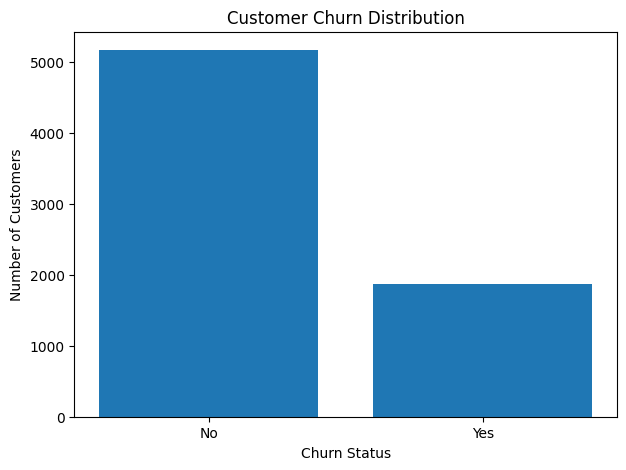

In [18]:
import matplotlib.pyplot as plt

churn_count = df['Churn'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(churn_count.index, churn_count.values)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

In [19]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


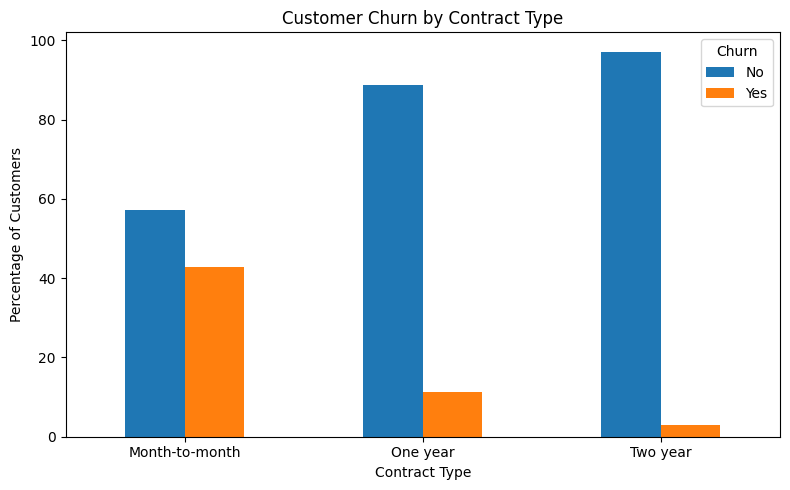

In [20]:
contract_churn.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

In [21]:
tenure_churn = df.groupby('Churn')['tenure'].describe()

print(tenure_churn)

        count       mean        std  min   25%   50%   75%   max
Churn                                                           
No     5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0


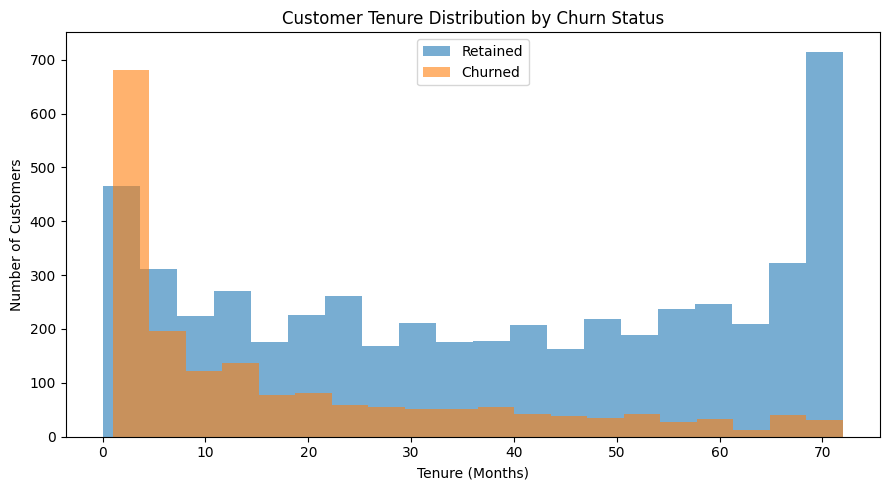

In [22]:
plt.figure(figsize=(9, 5))

plt.hist(
    df[df['Churn'] == 'No']['tenure'],
    bins=20,
    alpha=0.6,
    label='Retained'
)

plt.hist(
    df[df['Churn'] == 'Yes']['tenure'],
    bins=20,
    alpha=0.6,
    label='Churned'
)

plt.title('Customer Tenure Distribution by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


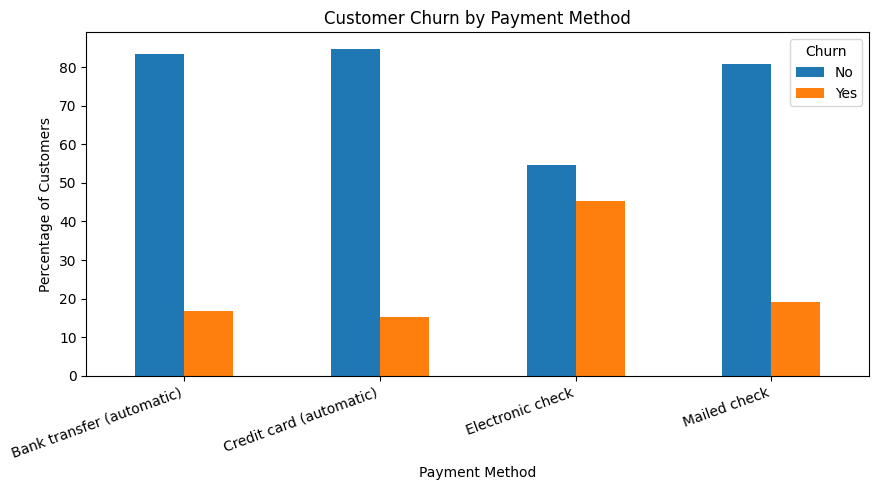

In [24]:
payment_churn.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

In [25]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


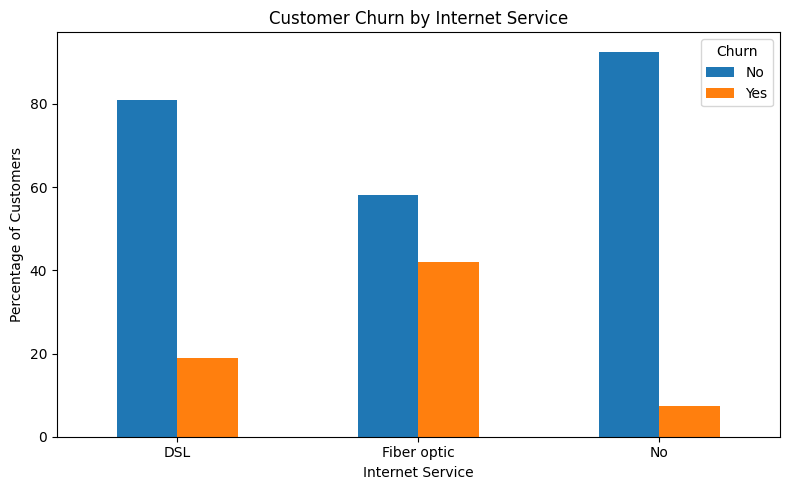

In [26]:
internet_churn.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

In [27]:
monthly_charges = df.groupby('Churn')['MonthlyCharges'].describe()

print(monthly_charges)

        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
No     5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
Yes    1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


<Figure size 800x500 with 0 Axes>

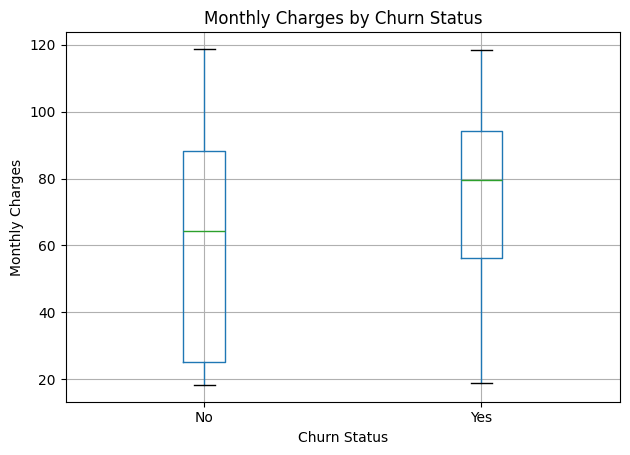

In [28]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column='MonthlyCharges',
    by='Churn'
)

plt.title('Monthly Charges by Churn Status')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')
plt.tight_layout()
plt.show()

In [29]:
senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

senior_churn.index = ['Non-Senior Citizen', 'Senior Citizen']

print(senior_churn.round(2))

Churn                  No    Yes
Non-Senior Citizen  76.39  23.61
Senior Citizen      58.32  41.68


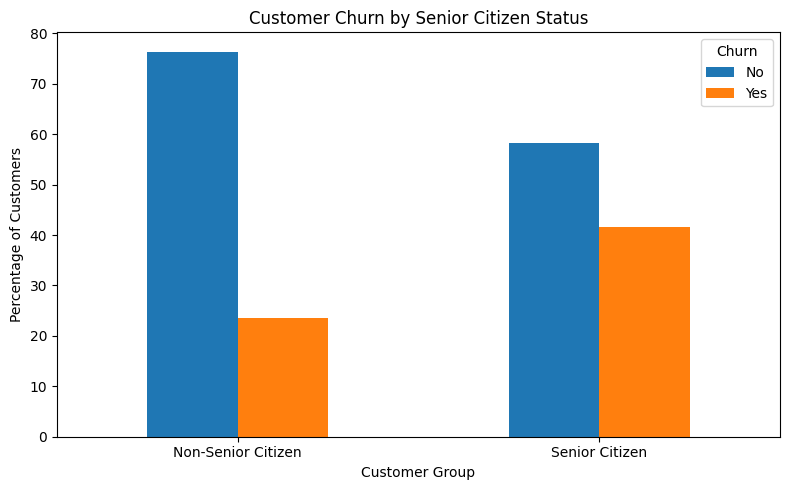

In [30]:
senior_churn.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Customer Churn by Senior Citizen Status')
plt.xlabel('Customer Group')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

In [31]:
partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

print(partner_churn.round(2))

Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66


In [32]:
dependent_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

print(dependent_churn.round(2))

Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45


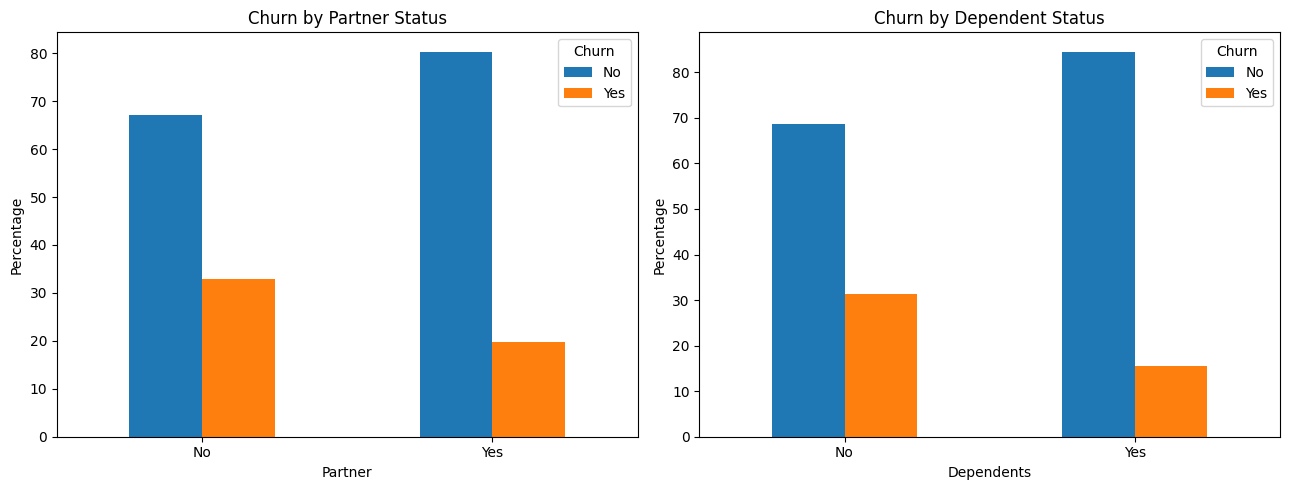

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

partner_churn.plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Churn by Partner Status')
axes[0].set_xlabel('Partner')
axes[0].set_ylabel('Percentage')
axes[0].tick_params(axis='x', rotation=0)

dependent_churn.plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Churn by Dependent Status')
axes[1].set_xlabel('Dependents')
axes[1].set_ylabel('Percentage')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [34]:
security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

print(security_churn.round(2))

Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


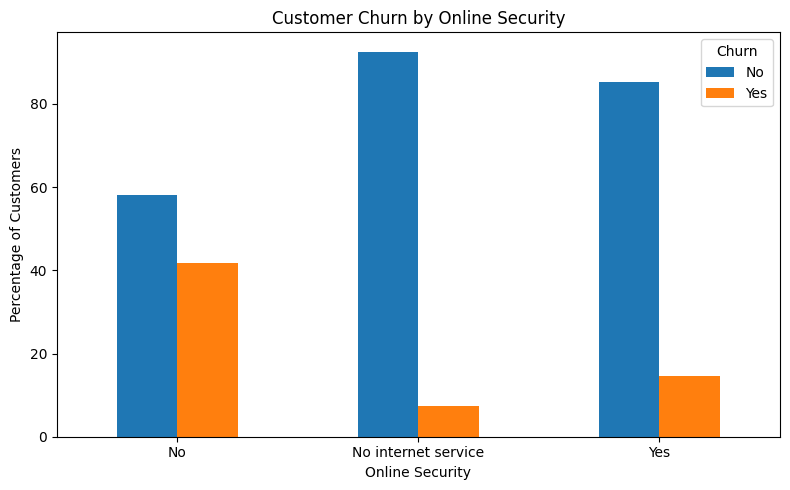

In [35]:
security_churn.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

In [36]:
support_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

print(support_churn.round(2))

Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


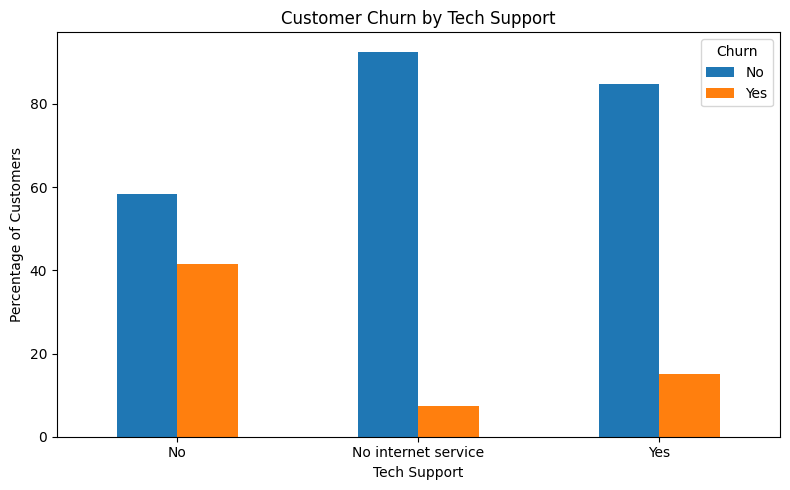

In [37]:
support_churn.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

TOTAL CHARGES BY CHURN STATUS
        count     mean      std    min    25%      50%      75%      max
Churn                                                                   
No     5174.0  2549.91  2329.95   0.00  572.9  1679.52  4262.85  8672.45
Yes    1869.0  1531.80  1890.82  18.85  134.5   703.55  2331.30  8684.80

ESTIMATED CUSTOMER VALUE BY CHURN STATUS
       count     mean   median    min     max
Churn                                        
No      5174  2549.77  1687.12   0.00  8550.0
Yes     1869  1531.61   700.00  18.85  8481.6


<Figure size 900x500 with 0 Axes>

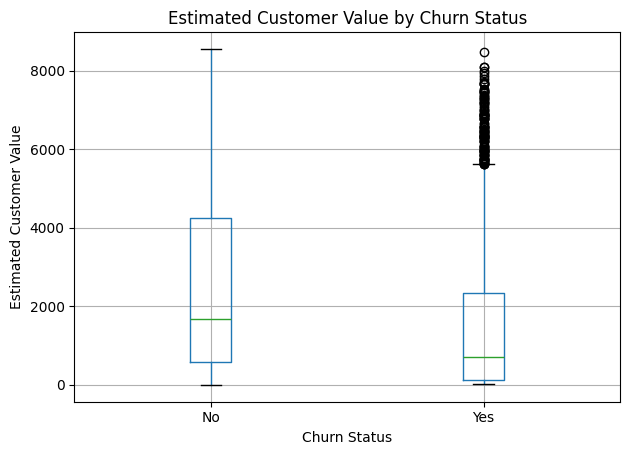

In [38]:
# Total Charges Analysis

total_charges = df.groupby('Churn')['TotalCharges'].describe()

print("TOTAL CHARGES BY CHURN STATUS")
print(total_charges.round(2))


# Estimated Customer Value

df['EstimatedCustomerValue'] = df['MonthlyCharges'] * df['tenure']

customer_value = df.groupby('Churn')['EstimatedCustomerValue'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print("\nESTIMATED CUSTOMER VALUE BY CHURN STATUS")
print(customer_value.round(2))


# Visualisation

plt.figure(figsize=(9, 5))

df.boxplot(
    column='EstimatedCustomerValue',
    by='Churn'
)

plt.title('Estimated Customer Value by Churn Status')
plt.suptitle('')
plt.xlabel('Churn Status')
plt.ylabel('Estimated Customer Value')
plt.tight_layout()
plt.show()

In [39]:
import os

# Create output folder
os.makedirs("outputs", exist_ok=True)

# Factors selected for churn analysis
factors = [
    'Contract',
    'PaymentMethod',
    'InternetService',
    'SeniorCitizen',
    'Partner',
    'Dependents',
    'OnlineSecurity',
    'TechSupport'
]

# Calculate churn rate for each category
churn_insights = []

for factor in factors:
    rates = df.groupby(factor, observed=True)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    )

    for category, rate in rates.items():
        churn_insights.append({
            'Factor': factor,
            'Category': category,
            'Churn_Rate': round(rate, 2)
        })

insights_df = pd.DataFrame(churn_insights)

# Overall churn summary
overall_summary = pd.DataFrame({
    'Metric': ['Total Customers', 'Retained Customers',
               'Churned Customers', 'Overall Churn Rate'],
    'Value': [
        len(df),
        (df['Churn'] == 'No').sum(),
        (df['Churn'] == 'Yes').sum(),
        round((df['Churn'] == 'Yes').mean() * 100, 2)
    ]
})

# Save results
df.to_csv("outputs/cleaned_customer_churn.csv", index=False)
insights_df.to_csv("outputs/churn_factor_summary.csv", index=False)
overall_summary.to_csv("outputs/overall_churn_summary.csv", index=False)

print("OVERALL CHURN SUMMARY")
print(overall_summary)

print("\nCHURN FACTOR SUMMARY")
print(insights_df.to_string(index=False))

print("\nAll analysis files saved successfully!")

OVERALL CHURN SUMMARY
               Metric    Value
0     Total Customers  7043.00
1  Retained Customers  5174.00
2   Churned Customers  1869.00
3  Overall Churn Rate    26.54

CHURN FACTOR SUMMARY
         Factor                  Category  Churn_Rate
       Contract            Month-to-month       42.71
       Contract                  One year       11.27
       Contract                  Two year        2.83
  PaymentMethod Bank transfer (automatic)       16.71
  PaymentMethod   Credit card (automatic)       15.24
  PaymentMethod          Electronic check       45.29
  PaymentMethod              Mailed check       19.11
InternetService                       DSL       18.96
InternetService               Fiber optic       41.89
InternetService                        No        7.40
  SeniorCitizen                         0       23.61
  SeniorCitizen                         1       41.68
        Partner                        No       32.96
        Partner                       Yes    

CUSTOMER RETENTION BY TENURE GROUP
              Total_Customers  Churned_Customers  Retained_Customers  \
TenureGroup                                                            
0-12 Months              2186               1037                1149   
13-24 Months             1024                294                 730   
25-48 Months             1594                325                1269   
49-72 Months             2239                213                2026   

              Churn_Rate  Retention_Rate  
TenureGroup                               
0-12 Months        47.44           52.56  
13-24 Months       28.71           71.29  
25-48 Months       20.39           79.61  
49-72 Months        9.51           90.49  


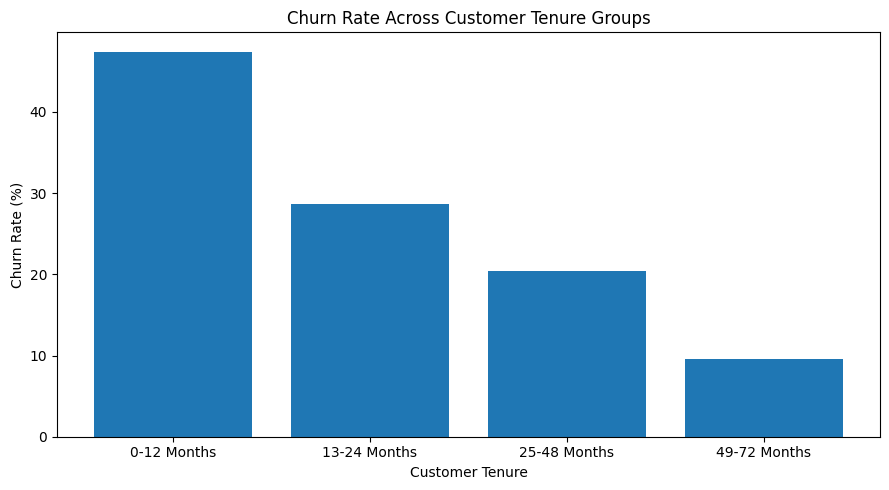


Tenure analysis saved successfully!


In [40]:
# Group customers by tenure
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 Months', '13-24 Months', '25-48 Months', '49-72 Months']
)

# Calculate customer count and churn rate
tenure_summary = df.groupby('TenureGroup', observed=False).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

tenure_summary['Retained_Customers'] = (
    tenure_summary['Total_Customers'] -
    tenure_summary['Churned_Customers']
)

tenure_summary['Churn_Rate'] = (
    tenure_summary['Churned_Customers'] /
    tenure_summary['Total_Customers'] * 100
)

tenure_summary['Retention_Rate'] = (
    tenure_summary['Retained_Customers'] /
    tenure_summary['Total_Customers'] * 100
)

print("CUSTOMER RETENTION BY TENURE GROUP")
print(tenure_summary.round(2))


# Visualisation
plt.figure(figsize=(9, 5))

plt.bar(
    tenure_summary.index.astype(str),
    tenure_summary['Churn_Rate']
)

plt.title('Churn Rate Across Customer Tenure Groups')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()


# Save results
tenure_summary.to_csv(
    'outputs/tenure_retention_summary.csv'
)

print("\nTenure analysis saved successfully!")

In [41]:
import pandas as pd
import numpy as np
recommendations = pd.DataFrame({
    'Finding': [
        'High churn among month-to-month customers',
        'High churn among electronic check users',
        'High churn among fiber optic customers',
        'High churn among senior citizens',
        'High churn among customers without Online Security',
        'High churn among customers without Tech Support',
        'Higher average monthly charges among churned customers',
        'Shorter average tenure among churned customers'
    ],

    'Evidence': [
        '42.71% churn rate',
        '45.29% churn rate',
        '41.89% churn rate',
        '41.68% churn rate',
        '41.77% churn rate',
        '41.64% churn rate',
        '74.44 compared with 61.27',
        '17.98 compared with 37.57 months'
    ],

    'Recommendation': [
        'Encourage customers to consider longer-term contracts.',
        'Promote automatic payment options.',
        'Investigate fiber optic customer satisfaction and service quality.',
        'Provide suitable customer support and personalised retention offers.',
        'Promote Online Security packages.',
        'Improve awareness and accessibility of technical support.',
        'Review pricing plans and provide suitable packages.',
        'Introduce early-stage customer engagement and retention programmes.'
    ]
})

print("BUSINESS INSIGHTS AND RECOMMENDATIONS")
print(recommendations.to_string(index=False))
recommendations.to_csv(
    'outputs/business_recommendations.csv',
    index=False
)

df.to_csv(
    'outputs/cleaned_customer_churn.csv',
    index=False
)

print("\nRecommendations and updated dataset saved successfully!")

BUSINESS INSIGHTS AND RECOMMENDATIONS
                                               Finding                         Evidence                                                       Recommendation
             High churn among month-to-month customers                42.71% churn rate               Encourage customers to consider longer-term contracts.
               High churn among electronic check users                45.29% churn rate                                   Promote automatic payment options.
                High churn among fiber optic customers                41.89% churn rate   Investigate fiber optic customer satisfaction and service quality.
                      High churn among senior citizens                41.68% churn rate Provide suitable customer support and personalised retention offers.
    High churn among customers without Online Security                41.77% churn rate                                    Promote Online Security packages.
       High churn am

In [8]:
import pandas as pd
print(pd.__version__)

2.3.3


In [6]:
import os
print(os.getcwd())


C:\Users\KUSHI\OneDrive\Documents\Desktop\FUTURE_DS_02
